# 01 — Preparação dos dados

**Enunciado etapa 1** \
Preparação dos dados: verifique os tipos das variáveis, valores ausentes, registros
duplicados e possíveis inconsistências. Examine especialmente a conversão de
TotalCharges para formato numérico. Defina o tratamento das variáveis
categóricas e justifique a exclusão do identificador customerID dos preditores.

**Saídas deste notebook**:
- `data/processed/telco_clean.csv` — base completa limpa
- `data/processed/train.csv` e `test.csv` — divisão estratificada 80/20

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Leitura do CSV
df = pd.read_csv('../data/raw/telco_churn_data.csv')
df_eda = df.copy()
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Pela descrição do Kaggle, o dicionário de colunas contém as seguintes informações:
- Customers who left within the last month – the column is called Churn
- Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
- Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges
- Demographic info about customers – gender, age range, and if they have partners and dependents

## 1. Tipos das variáveis

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
# Quantidade de valores distintos de cada variável
display(df.nunique().to_frame("valores distintos"))

# Categorias de cada variável de texto (exceto customerID e TotalCharges, que têm um valor por cliente)
for col in df.select_dtypes(exclude="number").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col:17s}", list(df[col].unique()))

,valores distintos
customerID,7043
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
tenure,73
PhoneService,2
MultipleLines,3
InternetService,3
OnlineSecurity,3


gender            ['Female', 'Male']
Partner           ['Yes', 'No']
Dependents        ['No', 'Yes']
PhoneService      ['No', 'Yes']
MultipleLines     ['No phone service', 'No', 'Yes']
InternetService   ['DSL', 'Fiber optic', 'No']
OnlineSecurity    ['No', 'Yes', 'No internet service']
OnlineBackup      ['Yes', 'No', 'No internet service']
DeviceProtection  ['No', 'Yes', 'No internet service']
TechSupport       ['No', 'Yes', 'No internet service']
StreamingTV       ['No', 'Yes', 'No internet service']
StreamingMovies   ['No', 'Yes', 'No internet service']
Contract          ['Month-to-month', 'One year', 'Two year']
PaperlessBilling  ['Yes', 'No']
PaymentMethod     ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn             ['No', 'Yes']


Observações sobre os tipos:
- `tenure` (int), `MonthlyCharges` (float) e `SeniorCitizen` (int) já foram lidos como numéricos.
- `SeniorCitizen` já está codificada em 0/1, enquanto as outras binárias (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, `Churn`) estão como "Yes"/"No". Vou padronizá-las para 0/1.
- `TotalCharges` foi lida como`str`, mas deveria ser numérica
- Nenhuma coluna tem valores `NaN` na leitura
- `customerID` tem um valor distinto por linha. Não há IDs repetidos

## 2. Tratamento de variáveis

### 2.1 Variáveis categóricas

- Serviços com categoria redundante (`MultipleLines` e os 6 serviços de internet):
    * Aqui, vou investigar se a categoria "No internet service" só aparece quando `InternetService == "No"` e "No phone service" quando `PhoneService == "No"`. Se sim, vou juntar essas categorias com "No", removendo a redundância e tornando a variável binária.

In [5]:
# "No internet service" deve ocorrer exatamente quando InternetService == "No"
# (e "No phone service" exatamente quando PhoneService == "No")
SERVICOS_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                     "TechSupport", "StreamingTV", "StreamingMovies"]

sem_internet = df["InternetService"] == "No"
for col in SERVICOS_INTERNET:
    print(f"{col:17s}", ((df[col] == "No internet service") == sem_internet).all())

sem_telefone = df["PhoneService"] == "No"
print(f"{'MultipleLines':17s}", ((df["MultipleLines"] == "No phone service") == sem_telefone).all())

OnlineSecurity    True
OnlineBackup      True
DeviceProtection  True
TechSupport       True
StreamingTV       True
StreamingMovies   True
MultipleLines     True


Ou seja, conclui-se que toda vez que "No internet service" aparece nas variáveis de serviços de internet, `InternetService == "No"` e toda vez que "No phone service" aparece em MultipleLines, `PhoneService == "No"`. Portanto, "No internet service" e "No phone service" viram "No"

Entretanto, para a análise exploratória, as categorias "No internet service"/"No phone service" e "No" provavelmente possuem taxas de churn distintas, e contém informação nelas. Por esse motivo, realizar essas alterações apenas no ´df´, que será utilizado para modelagem, e não no df_eda, que será a base que será utilizada na Análise Exploratória

In [6]:
 # Junta a categoria redundante com "No": sem o serviço base, o cliente também não tem o adicional
for col in SERVICOS_INTERNET:
    df[col] = df[col].replace("No internet service", "No")
df["MultipleLines"] = df["MultipleLines"].replace("No phone service", "No")

- Variáveis binárias (`gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `PaperlessBilling`, `Churn` e os serviços de internet após o tratamento acima):
    * São convertidas para 0 e 1.
    * `gender` passa a se chamar `is_male` (1 = Male)
    * `SeniorCitizen` já está em 0 e 1.

In [7]:
# Binárias -> 0/1
BINARIAS = ["Partner", "Dependents", "PhoneService", "PaperlessBilling", "Churn", *SERVICOS_INTERNET]
for col in BINARIAS:
    df[col] = df[col].map({"Yes": 1, "No": 0})

df["gender"] = df["gender"].map({"Male": 1, "Female": 0})
df['MultipleLines'] = df['MultipleLines'].map({"Yes": 1, "No": 0})
df = df.rename(columns={"gender": "is_male"})

Para as variáveis categóricas não binárias `InternetService`, `Contract`, `PaymentMethod`, será feito o one-hot encoding mais adiante. Porém, ainda vou deixá-las do jeito que estão para a análise exploratória.

### 2.2 Variável TotalCharges

A variável `TotalCharges` foi lida como `str`. Portanto, vamos explorar seus valores

In [8]:
tc = pd.to_numeric(df["TotalCharges"], errors="coerce")
tc_eda = pd.to_numeric(df_eda["TotalCharges"], errors="coerce") # Essa alteração também é feita para a base que irá ser usada na EDA

print("Valores que não foram convertidos:", tc.isna().sum())
df.loc[tc.isna(), ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Valores que não foram convertidos: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,0
753,3115-CZMZD,0,20.25,,0
936,5709-LVOEQ,0,80.85,,0
1082,4367-NUYAO,0,25.75,,0
1340,1371-DWPAZ,0,56.05,,0
3331,7644-OMVMY,0,19.85,,0
3826,3213-VVOLG,0,25.35,,0
4380,2520-SGTTA,0,20.00,,0
5218,2923-ARZLG,0,19.70,,0
6670,4075-WKNIU,0,73.35,,0


Os 11 registros são valores em branco, e todos têm tenure == 0. Ou seja, são clientes que acabaram de entrar e ainda não receberam cobrança. Aqui verifico se vale para todos os casos

In [9]:
print("Todo valor em branco tem tenure == 0:", (df.loc[tc.isna(), "tenure"] == 0).all())
print("Todo tenure == 0 é valor em branco:  ", (df["tenure"] == 0).sum() == tc.isna().sum())

Todo valor em branco tem tenure == 0: True
Todo tenure == 0 é valor em branco:   True


Vale para todos os casos. Então, valores em branco são preenchidos com 0

In [10]:
df["TotalCharges"] = tc.fillna(0)
df_eda["TotalCharges"] = tc.fillna(0) # base EDA


* Explorando se `MonthlyCharges × tenure` bate com `TotalCharges`

Teoricamente, o total cobrado de um cliente deve ser aproximadamente a mensalidade vezes o número de meses. A igualdade talvez não seja exata devido à mudanças no valor da mensalidade do cliente ao longo do tempo, porém aqui espera-se que `MonthlyCharges × tenure` tenha uma alta correlação com `TotalCharges`

In [11]:
estimado = df["MonthlyCharges"] * df["tenure"]
com_cobranca = df["tenure"] > 0  # evita divisão por zero
dif_relativa = ((df["TotalCharges"] - estimado) / estimado)[com_cobranca]

print(f"Correlação: {df['TotalCharges'].corr(estimado):.4f}")
print(f"Diferença relativa de até 5%:  {(dif_relativa.abs() <= 0.05).mean():.1%}")
print(f"Diferença relativa de até 10%: {(dif_relativa.abs() <= 0.10).mean():.1%}")
dif_relativa.describe(percentiles=[.01, .05, .5, .95, .99]).round(3).to_frame("dif. relativa")

Correlação: 0.9996
Diferença relativa de até 5%:  80.4%
Diferença relativa de até 10%: 94.6%


,dif. relativa
count,7032.000
mean,0.000
std,0.051
min,-0.311
1%,-0.145
5%,-0.076
50%,0.000
95%,0.075
99%,0.159
max,0.573


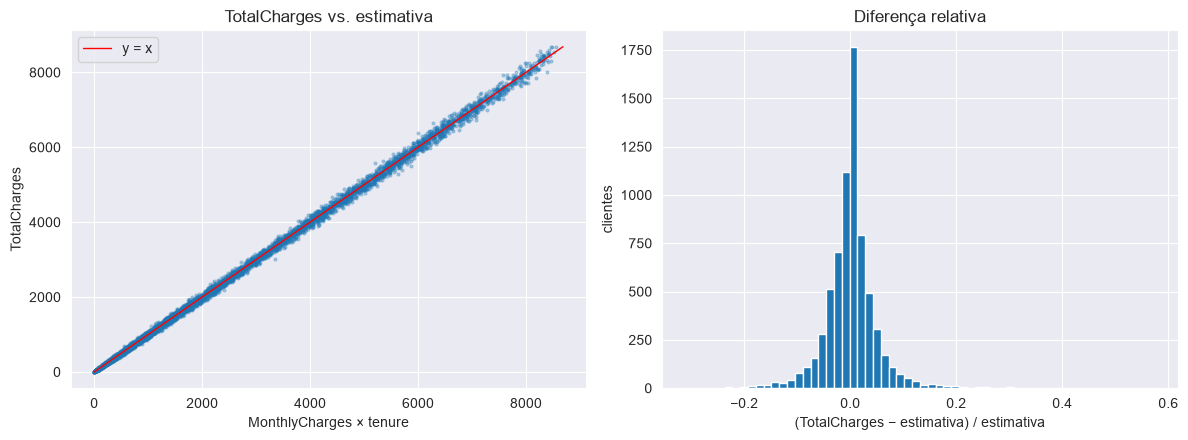

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

lim = df["TotalCharges"].max()
axes[0].scatter(estimado, df["TotalCharges"], s=4, alpha=0.3)
axes[0].plot([0, lim], [0, lim], color="red", lw=1, label="y = x")
axes[0].set(xlabel="MonthlyCharges × tenure", ylabel="TotalCharges", title="TotalCharges vs. estimativa")
axes[0].legend()

axes[1].hist(dif_relativa, bins=60)
axes[1].set(xlabel="(TotalCharges − estimativa) / estimativa", ylabel="clientes", title="Diferença relativa")

plt.tight_layout()
plt.show()

Portanto, não há inconsistência que exija correção. `TotalCharges` é redundante com `tenure` e `MonthlyCharges`, o que será levado em conta na seleção de variáveis

* Faixas das variáveis numéricas

Verificando se há valores impossíveis (negativos, mensalidade zero, tenure acima do esperado)

In [13]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe(percentiles=[.01,.25, .5, .75, .9, .99]).round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
1%,1.00,19.20,19.75
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
90%,69.00,102.60,5973.69
99%,72.00,114.73,8039.26


Não há valores negativos nem fora do esperado. Os valores fazem sentido

## 3. Valores ausentes

In [14]:
df.isna().sum()

customerID          0
is_male             0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

A base não possui mais valores nulos

## 4. Valores duplicados

In [15]:
print("Linhas duplicadas (todas as colunas):", df.duplicated().sum())
print("customerID repetidos:", df['customerID'].duplicated().sum())
print("Linhas idênticas ignorando o customerID:", df.drop(columns='customerID').duplicated().sum())

Linhas duplicadas (todas as colunas): 0
customerID repetidos: 0
Linhas idênticas ignorando o customerID: 22


In [16]:
# Exemplos de clientes diferentes com exatamente o mesmo perfil
dup = df.drop(columns='customerID').duplicated(keep=False)
print(f'Clientes com perfil duplicado: {dup.sum()}')
df[dup].sort_values(["tenure", "MonthlyCharges"]).head(8)

Clientes com perfil duplicado: 42


,customerID,is_male,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
542,2866-IKBTM,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.55,19.55,0
1491,8605-ITULD,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.55,19.55,0
5170,7721-DVEKZ,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.65,19.65,0
6774,0970-QXPXW,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.65,19.65,0
4817,6654-QGBZZ,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.90,19.90,0
6706,7878-RTCZG,0,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,19.90,19.90,0
662,3030-ZKIWL,1,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,20.05,20.05,0
3754,7096-UCLNH,1,0,0,0,1,1,0,No,0,...,0,0,0,0,Month-to-month,0,Mailed check,20.05,20.05,0


Não há customerID repetido, e 20 perfis aparecem mais de uma vez, somando 42 clientes. Considero esses registros legítimos, e não erros de duplicação. Portanto decido mantê-los

## 5. Salvar a base limpa

O `customerID` é mantido no arquivo para identificar os clientes, mas não entrará como preditor nos modelos

In [17]:
df.to_csv("../data/processed/telco_clean.csv", index=False)
df_eda.to_csv("../data/processed/telco_eda.csv", index=False)
df.dtypes

customerID              str
is_male               int64
SeniorCitizen         int64
Partner               int64
Dependents            int64
tenure                int64
PhoneService          int64
MultipleLines         int64
InternetService         str
OnlineSecurity        int64
OnlineBackup          int64
DeviceProtection      int64
TechSupport           int64
StreamingTV           int64
StreamingMovies       int64
Contract                str
PaperlessBilling      int64
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object

## 6. Divisão estratificada treino/teste

Divisão estratificada pelo target (`Churn`), mantendo a mesma proporção no treino e no teste. Proporção de 80% para o treino e 20% para o teste.

In [18]:
train, test = train_test_split(df, test_size=0.2, stratify=df["Churn"], random_state=42)
train.to_csv("../data/processed/train.csv", index=False)
test.to_csv("../data/processed/test.csv", index=False)

pd.DataFrame({
    "n": [len(df), len(train), len(test)],
    "taxa de churn": [df["Churn"].mean(), train["Churn"].mean(), test["Churn"].mean()],
}, index=["total", "treino", "teste"]).round(4)

,n,taxa de churn
total,7043,0.2654
treino,5634,0.2654
teste,1409,0.2654
